In [1]:
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, BatchNormalization
from tensorflow.keras.models import Sequential
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint
import matplotlib.pyplot as plt

import seaborn as sns
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np
from keras.preprocessing import image

In [2]:
# mnist
from keras.datasets import mnist

In [3]:
(x_train,y_train),(x_test,y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [5]:
type(x_train)

numpy.ndarray

In [4]:
#shape of my numpy array
print(x_train.shape , y_train.shape,x_test.shape,y_test.shape)

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


Training data = 60,000 images
Test data = 10,000 images
 image dimension --> 28x

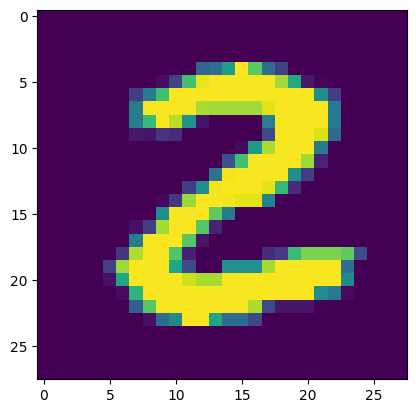

2


In [6]:
#displaying the image
plt.imshow(x_train[25])
plt.show()

# print the corresponding label
print(y_train[25])

In [7]:
# unique values in y_train
print(np.unique(y_train))

#unique values in y_test
print(np.unique(y_test))

[0 1 2 3 4 5 6 7 8 9]
[0 1 2 3 4 5 6 7 8 9]


In [8]:
#scaling the values
x_train = x_train/255
x_test = x_test/255

Building the neural network

In [11]:
from tensorflow import keras
#setting up the layers of the neural network
model = keras.Sequential([
                           keras.layers.Flatten(input_shape=(28,28)),
                           keras.layers.Dense(50, activation = 'relu'),
                           keras.layers.Dense(50, activation = 'relu'),
                           keras.layers.Dense(10, activation = 'sigmoid'),
                           
])

c:\Users\ahile\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
# compiling the neural network
model.compile(optimizer='adam',
              loss ='sparse_categorical_crossentropy',
              metrics= ['accuracy'])

In [13]:
model.fit(x_train,y_train,epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9118 - loss: 0.3024
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9563 - loss: 0.1445
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9679 - loss: 0.1060
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9736 - loss: 0.0855
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9774 - loss: 0.0712
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9809 - loss: 0.0599
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9837 - loss: 0.0535
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9851 - loss: 0.0461
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9873 - loss: 0.0402
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9875 - loss: 0.0372


In [14]:
loss,accuracy = model.evaluate(x_test,y_test)
print(accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9706 - loss: 0.1121
0.9706000089645386


In [16]:
a=[11,225,35,21,56]
import numpy as np
np.argmax(a)

np.int64(1)

In [19]:
print(y_test[0])

7


In [15]:
y_pred = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


In [17]:
print(y_pred.shape)

(10000, 10)


In [18]:
print(y_pred[0])

[4.1362530e-01 6.5746007e-04 9.8730755e-01 9.9049914e-01 7.0415035e-06
 1.1846828e-02 2.0286496e-12 9.9999988e-01 2.6351520e-01 2.5375497e-01]


model.predict() --> gives the prediction probability of each class for that data point

In [20]:
# converting the prediction probabilities to class label

label_for_first_test_image = np.argmax(y_pred[0])
print(label_for_first_test_image)

7


In [23]:
# converting the prediction probabilities to class label for all test data points
y_pred_label =[np.argmax(i) for i in y_pred]
print(y_pred_label)

[np.int64(7), np.int64(2), np.int64(1), np.int64(0), np.int64(4), np.int64(1), np.int64(4), np.int64(9), np.int64(5), np.int64(9), np.int64(0), np.int64(6), np.int64(9), np.int64(0), np.int64(1), np.int64(5), np.int64(9), np.int64(7), np.int64(3), np.int64(4), np.int64(9), np.int64(6), np.int64(6), np.int64(5), np.int64(4), np.int64(0), np.int64(7), np.int64(4), np.int64(0), np.int64(1), np.int64(3), np.int64(1), np.int64(3), np.int64(4), np.int64(7), np.int64(2), np.int64(7), np.int64(1), np.int64(2), np.int64(1), np.int64(1), np.int64(7), np.int64(4), np.int64(2), np.int64(3), np.int64(5), np.int64(1), np.int64(2), np.int64(4), np.int64(4), np.int64(6), np.int64(3), np.int64(5), np.int64(5), np.int64(6), np.int64(0), np.int64(4), np.int64(1), np.int64(9), np.int64(5), np.int64(7), np.int64(8), np.int64(9), np.int64(3), np.int64(7), np.int64(4), np.int64(6), np.int64(4), np.int64(3), np.int64(0), np.int64(7), np.int64(0), np.int64(2), np.int64(9), np.int64(1), np.int64(7), np.int64(3)

y_test --> True labels
y_pred_labels --> Predicted labels
confusion matrix

In [24]:
conf_mat = confusion_matrix(y_test, y_pred_label)

In [25]:
print(conf_mat)

[[ 964    0    1    4    1    4    1    1    3    1]
 [   0 1127    1    4    0    0    0    1    2    0]
 [   4    1 1007    8    1    0    2    5    2    2]
 [   0    0    4  999    0    0    0    3    4    0]
 [   4    0    7    0  950    1    6    4    1    9]
 [   3    0    1   25    1  850    7    0    3    2]
 [   9    4    3    1    5    7  927    0    2    0]
 [   2    2   11    3    1    0    0 1003    1    5]
 [   3    0    7   16    3    8    2    7  926    2]
 [   4    4    0   11   10    1    1   17    7  954]]


Text(0.5, 47.7222222222222, 'Predicted Labels')

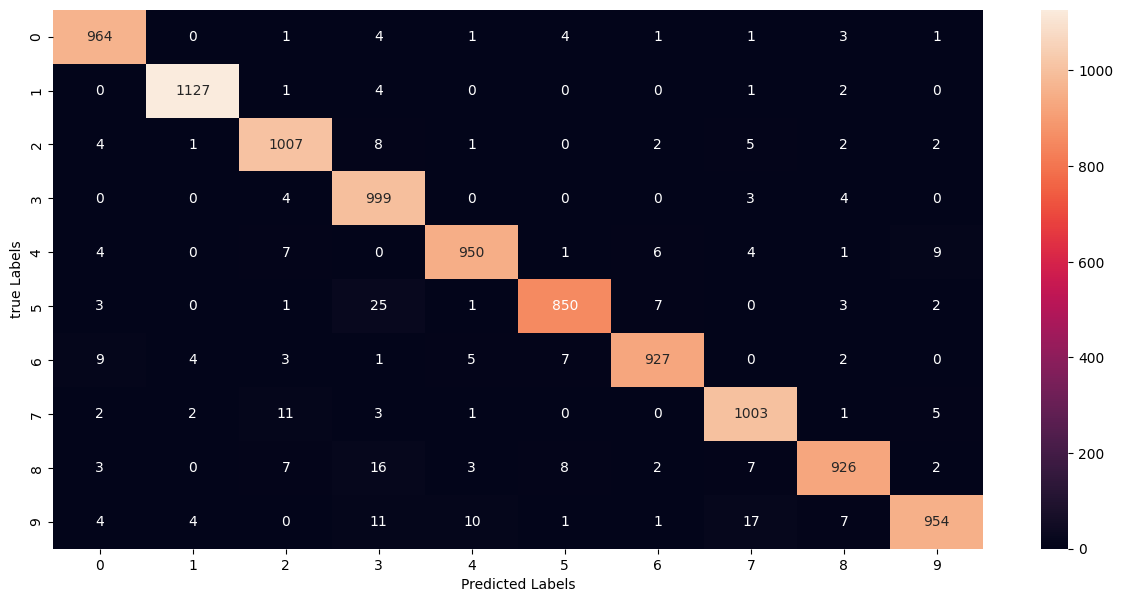

In [26]:
plt.figure(figsize=(15,7))
sns.heatmap(conf_mat,annot=True, fmt='d')
plt.ylabel('true Labels')
plt.xlabel('Predicted Labels')